Let's implement a 3D EKF. First, a bit of theory on attitude dynamics: how our object is oriented in space relative to a reference frame.

# Attitude Kinematics: Direction Cosine Matrix & Euler Angles

## 1. Direction Cosine Matrix (DCM) & Attitude Dynamics

![](docs/img/dcm.png)

$$\hat{b} = C\hat{n}$$

$$\begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix} = \begin{bmatrix} C_{11} & C_{12} & C_{13} \\ C_{21} & C_{22} & C_{23} \\ C_{31} & C_{32} & C_{33} \end{bmatrix} \begin{bmatrix} \hat{n}_1 \\ \hat{n}_2 \\ \hat{n}_3 \end{bmatrix}$$

* $x_N = C^T x_B \leftarrow$ represent point $x$ in terms of $N$-frame (world frame)
* $C$ will change with time $(C(t))$  due to dynamics $(\omega)$ the body is rotating, thus the transformation from body to world frame changes
* We will typically have $\omega$ in terms of body frame:
  $$\omega_B = \begin{bmatrix} \omega_1 \\ \omega_2 \\ \omega_3 \end{bmatrix}_B = \begin{bmatrix} \omega_{B1} \\ \omega_{B2} \\ \omega_{B3} \end{bmatrix} = \omega_1 \hat{b}_1 + \omega_2 \hat{b}_2 + \omega_3 \hat{b}_3 = \begin{bmatrix} \omega_1 & \omega_2 & \omega_3 \end{bmatrix} \begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix}$$

$\hookrightarrow$ **We want to find out how $C$ changes with the dynamics $\omega_B$.**

### Transport Theorem

**Relates the time derivative of any vector as observed in a non-rotating (inertial) frame to its time derivative as observed in a rotating frame.**

$$\left(\frac{d\vec{r}}{dt}\right)_{\text{fixed}} = \left(\frac{d\vec{r}}{dt}\right)_{\text{rotating}} + \vec{\Omega} \times \vec{r}$$

* $\vec{r}$ is any vector
* $\vec{\Omega}$ is the angular velocity of the rotating frame relative to the fixed frame

$\hookrightarrow$ For our case:

$$\left(\frac{d\hat{b}_1}{dt}\right)_N = \underbrace{\left(\frac{d\hat{b}_1}{dt}\right)_B}_{0} + \omega_B \times \hat{b}_1$$

$$[\tilde{\omega}_B] = \begin{bmatrix} 0 & -\omega_3 & \omega_2 \\ \omega_3 & 0 & -\omega_1 \\ -\omega_2 & \omega_1 & 0 \end{bmatrix}$$

$$= \omega_B \times \hat{b}_1 = [\tilde{\omega}]_B \hat{b}_1 = \begin{bmatrix} 0 & -\omega_3 & \omega_2 \\ \omega_3 & 0 & -\omega_1 \\ -\omega_2 & \omega_1 & 0 \end{bmatrix}_B \begin{bmatrix} 1 \\ 0 \\ 0 \end{bmatrix} = \begin{bmatrix} 0 \\ \omega_3 \\ -\omega_2 \end{bmatrix}_B = \omega_3 \hat{b}_2 - \omega_2 \hat{b}_3 = \begin{bmatrix} 0 & \omega_3 & -\omega_2 \end{bmatrix} \begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix}$$

$\hookrightarrow$ Do the same for $\hat{b}_2, \hat{b}_3$:

$$\left(\frac{d\hat{b}_2}{dt}\right)_N = \begin{bmatrix} -\omega_3 & 0 & \omega_1 \end{bmatrix} \begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix}$$

$$\left(\frac{d\hat{b}_3}{dt}\right)_N = \begin{bmatrix} \omega_2 & -\omega_1 & 0 \end{bmatrix} \begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix}$$

$\hookrightarrow$ These 3 $\omega$ rows look like $-[\tilde{\omega}_B]$, so rewrite compacted:

$$\left(\frac{d\hat{b}}{dt}\right)_N = -[\tilde{\omega}_B]\hat{b}$$

### Deriving $\dot{C}$

$\hookrightarrow$ Substitute in $\hat{b} = C\hat{n}$:

* **Left hand side:**
  $$\left(\frac{d\hat{b}}{dt}\right)_N = \left(\frac{d}{dt} C\hat{n}\right)_N = \left(\frac{d}{dt} C\right)\hat{n} + C \underbrace{\left(\frac{d}{dt}\hat{n}\right)_N}_{0}$$
* **Right hand side:**
  $$-[\tilde{\omega}_B]\hat{b} = -[\tilde{\omega}_B]C\hat{n}$$

$\hookrightarrow$ Combine:

$$\left(\frac{d}{dt} C\right)\hat{n} = -[\tilde{\omega}_B]C\hat{n} \implies \frac{d}{dt} C = -[\tilde{\omega}_B]C \implies \dot{C} = -[\tilde{\omega}_B]C$$

So, $\hat{b} = C\hat{n}$ *(rotates fixed frame $N$ to body frame $B$)*:

$$\begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix} = \begin{bmatrix} C_{11} & C_{12} & C_{13} \\ C_{21} & C_{22} & C_{23} \\ C_{31} & C_{32} & C_{33} \end{bmatrix} \begin{bmatrix} \hat{n}_1 \\ \hat{n}_2 \\ \hat{n}_3 \end{bmatrix}$$

and *(how $C$ changes with time based on body dynamics)*:

$$\dot{C} = -[\tilde{\omega}_B]C = -\begin{bmatrix} 0 & -\omega_3 & \omega_2 \\ \omega_3 & 0 & -\omega_1 \\ -\omega_2 & \omega_1 & 0 \end{bmatrix} \begin{bmatrix} C_{11} & C_{12} & C_{13} \\ C_{21} & C_{22} & C_{23} \\ C_{31} & C_{32} & C_{33} \end{bmatrix} \implies \begin{cases} \dot{C}_{11} = C_{21}\omega_3 - C_{31}\omega_2 \\ \dot{C}_{12} = C_{22}\omega_3 - C_{32}\omega_2 \\ \dots \end{cases}$$

---


## 2. Rotation Matrix (Euler Angle Parameterization)

**Why Euler?** Because the rotation matrix has 9 parameters, which is redundant for 3D rotation. Euler introduces a more intuitive way of representing a rotation as a parameterization of roll, pitch, yaw.

### Sequential Rotations (3-2-1 Sequence)

* Rotate about $\hat{n}_3 \xrightarrow{\text{yaw}} \hat{b}'_1, \hat{b}'_2, \hat{b}'_3$
* Rotate about $\hat{b}'_2 \xrightarrow{\text{pitch}} \hat{b}''_1, \hat{b}''_2, \hat{b}''_3$
* Rotate about $\hat{b}''_1 \xrightarrow{\text{roll}} \hat{b}_1, \hat{b}_2, \hat{b}_3 \longrightarrow$ *no prime because it represents the actual object orientation after all rotations are applied*

Because when rotating about an axis, the axis stays fixed:

$$\begin{aligned}
\hat{b}'_3 &= \hat{n}_3 \\
\hat{b}''_2 &= \hat{b}'_2 \\
\hat{b}_1 &= \hat{b}''_1
\end{aligned}$$

### Elementary Rotation Matrices

1. **Yaw ($\psi$) about axis 3:**
   $$\begin{bmatrix} \hat{b}'_1 \\ \hat{b}'_2 \\ \hat{b}'_3 \end{bmatrix} = \overbrace{\begin{bmatrix} \cos\psi & \sin\psi & 0 \\ -\sin\psi & \cos\psi & 0 \\ 0 & 0 & 1 \end{bmatrix}}^{M_3(\psi)} \begin{bmatrix} \hat{n}_1 \\ \hat{n}_2 \\ \hat{n}_3 \end{bmatrix} \longrightarrow \hat{b}' = M_3(\psi)\hat{n}$$

2. **Pitch ($\theta$) about axis 2:**
   $$\begin{bmatrix} \hat{b}''_1 \\ \hat{b}''_2 \\ \hat{b}''_3 \end{bmatrix} = \overbrace{\begin{bmatrix} \cos\theta & 0 & -\sin\theta \\ 0 & 1 & 0 \\ \sin\theta & 0 & \cos\theta \end{bmatrix}}^{M_2(\theta)} \begin{bmatrix} \hat{b}'_1 \\ \hat{b}'_2 \\ \hat{b}'_3 \end{bmatrix} \longrightarrow \hat{b}'' = M_2(\theta)\hat{b}'$$

3. **Roll ($\phi$) about axis 1:**
   $$\begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix} = \overbrace{\begin{bmatrix} 1 & 0 & 0 \\ 0 & \cos\phi & \sin\phi \\ 0 & -\sin\phi & \cos\phi \end{bmatrix}}^{M_1(\phi)} \begin{bmatrix} \hat{b}''_1 \\ \hat{b}''_2 \\ \hat{b}''_3 \end{bmatrix} \longrightarrow \hat{b} = M_1(\phi)\hat{b}''$$

### Combined Transformation

$$\begin{aligned}
\hat{b} &= M_1(\phi)\hat{b}'' \\
&= M_1(\phi)M_2(\theta)\hat{b}' \\
&= \underbrace{M_1(\phi)M_2(\theta)M_3(\psi)}_{C(\psi, \theta, \phi)} \hat{n}
\end{aligned}$$

---

## Euler Angles & Kinematic Differential Equations

$$\hat{b} = M_1(\phi)M_2(\theta)M_3(\psi)\hat{n}$$

* **Translational kinematic differential equation:**
  $$\begin{bmatrix} \dot{x}(t) \\ \dot{y}(t) \\ \dot{z}(t) \end{bmatrix} = I_{3\times 3} \begin{bmatrix} v_x(t) \\ v_y(t) \\ v_z(t) \end{bmatrix}$$

* **Rotational kinematic differential equation:**
  $$\begin{bmatrix} \dot{\psi}(t) \\ \dot{\theta}(t) \\ \dot{\phi}(t) \end{bmatrix} = \underbrace{\begin{bmatrix} \cdot & \cdot & \cdot \\ \cdot & \cdot & \cdot \\ \cdot & \cdot & \cdot \end{bmatrix}}_{B(\psi, \theta, \phi)} \begin{bmatrix} \omega_1 \\ \omega_2 \\ \omega_3 \end{bmatrix}_B$$

$\hookrightarrow$ **What is the $B(\psi, \theta, \phi)$ matrix?** We look at the Euler angle sequence of rotations, and for each rotation, we write the time rate of change of one of the Euler angles and an axis of rotation (which is different for each rotation).

$\hookrightarrow$ Initially, the world frame is aligned with the body frame ($\hat{n}_1 = \hat{b}_1,\; \hat{n}_2 = \hat{b}_2,\; \hat{n}_3 = \hat{b}_3$).

<img src="docs/img/initial_frame.png" width="500"/>

* **1st rotation about $\hat{n}_3 = \hat{b}'_3$:**

<img src="docs/img/yaw_rotation.png" width="500"/>

  $$\omega_{B'/N} = \dot{\psi}\hat{b}'_3$$
  $$\begin{bmatrix} \hat{b}'_1 \\ \hat{b}'_2 \\ \hat{b}'_3 \end{bmatrix} = \begin{bmatrix} \cos\psi & \sin\psi & 0 \\ -\sin\psi & \cos\psi & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} \hat{n}_1 \\ \hat{n}_2 \\ \hat{n}_3 \end{bmatrix}$$

* **2nd rotation about $\hat{b}'_2 = \hat{b}''_2$:**
  $$\omega_{B''/B'} = \dot{\theta}\hat{b}''_2$$
  $$\begin{bmatrix} \hat{b}''_1 \\ \hat{b}''_2 \\ \hat{b}''_3 \end{bmatrix} = \begin{bmatrix} \cos\theta & 0 & -\sin\theta \\ 0 & 1 & 0 \\ \sin\theta & 0 & \cos\theta \end{bmatrix} \begin{bmatrix} \hat{b}'_1 \\ \hat{b}'_2 \\ \hat{b}'_3 \end{bmatrix} = M_2(\theta)\hat{b}'$$

* **3rd rotation about $\hat{b}''_1 = \hat{b}_1$:**
  $$\omega_{B/B''} = \dot{\phi}\hat{b}_1$$
  $$\begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix} = \begin{bmatrix} 1 & 0 & 0 \\ 0 & \cos\phi & \sin\phi \\ 0 & -\sin\phi & \cos\phi \end{bmatrix} \begin{bmatrix} \hat{b}''_1 \\ \hat{b}''_2 \\ \hat{b}''_3 \end{bmatrix} = M_1(\phi)\hat{b}''$$

### Total Angular Velocity in Body Frame

* **Total angular velocity:**
  $$\omega_{B/N} = \omega_{B/B''} + \omega_{B''/B'} + \omega_{B'/N} = \dot{\phi}\hat{b}_1 + \dot{\theta}\hat{b}''_2 + \dot{\psi}\hat{b}'_3$$

$\hookrightarrow$ We want to write in terms of $\hat{b}$ only:

$$\hat{b} = M_1(\phi)\hat{b}'' \longrightarrow \hat{b}'' = M_1(\phi)^T \hat{b}$$

$$\hat{b}'' = \begin{bmatrix} 1 & 0 & 0 \\ 0 & \cos\phi & -\sin\phi \\ 0 & \sin\phi & \cos\phi \end{bmatrix} \begin{bmatrix} \hat{b}_1 \\ \hat{b}_2 \\ \hat{b}_3 \end{bmatrix} \longrightarrow \hat{b}''_2 = \cos\phi\,\hat{b}_2 - \sin\phi\,\hat{b}_3$$

$$\hat{b}'' = M_2(\theta)\hat{b}' \longrightarrow \hat{b}' = M_2(\theta)^T \hat{b}'' = M_2(\theta)^T M_1(\phi)^T \hat{b}$$

$$\hat{b}'_3 = -\sin\theta\,\hat{b}_1 + \sin\phi\cos\theta\,\hat{b}_2 + \cos\phi\cos\theta\,\hat{b}_3$$

$\hookrightarrow$ Substituting into $\omega_{B/N}$:

$$\omega_{B/N} = (-\sin\theta\,\dot{\psi} + \dot{\phi})\hat{b}_1 + (\sin\phi\cos\theta\,\dot{\psi} + \cos\phi\,\dot{\theta})\hat{b}_2 + (\cos\phi\cos\theta\,\dot{\psi} - \sin\phi\,\dot{\theta})\hat{b}_3$$

$$\begin{bmatrix} \omega_1 \\ \omega_2 \\ \omega_3 \end{bmatrix}_B = \underbrace{\begin{bmatrix} -\sin\theta & 0 & 1 \\ \sin\phi\cos\theta & \cos\phi & 0 \\ \cos\phi\cos\theta & -\sin\phi & 0 \end{bmatrix}}_{B^{-1}(\psi, \theta, \phi)} \begin{bmatrix} \dot{\psi} \\ \dot{\theta} \\ \dot{\phi} \end{bmatrix}$$

### Inverted Kinematic Equation & Singularity

$$\begin{bmatrix} \dot{\psi} \\ \dot{\theta} \\ \dot{\phi} \end{bmatrix} = B(\psi, \theta, \phi)\omega_B = \begin{bmatrix} 0 & \frac{\sin\phi}{\cos\theta} & \frac{\cos\phi}{\cos\theta} \\ 0 & \cos\phi & -\sin\phi \\ 1 & \frac{\sin\phi\sin\theta}{\cos\theta} & \frac{\cos\phi\sin\theta}{\cos\theta} \end{bmatrix} \begin{bmatrix} \omega_1 \\ \omega_2 \\ \omega_3 \end{bmatrix}_B$$

$\hookrightarrow$ At $\theta = \frac{\pi}{2}\; (90^\circ) \rightarrow \cos\theta = 0 \rightarrow \begin{cases} \dot{\psi} \rightarrow \infty \\ \dot{\phi} \rightarrow \infty \end{cases}$

---

## EKF implementation

#### Continuous time kinematics

$\mathbf{x} = [p_x, p_y, p_z, v_x, v_y, v_z, \phi, \theta, \psi, b_{ax}, b_{ay}, b_{az}, b_{gx}, b_{gy}, b_{gz}]^T$

##### Why Euler angles over the rotation matrix ?
We represent the attitude of our object via Euler angles $\phi, \theta, \psi$ (roll, pitch, yaw).

The rotation matrix has 9 scalars, where each need to be a state in our state vector. A standard EKF updates its state via vector addition: $\hat{\mathbf{x}}^+ = \hat{\mathbf{x}}^- + K(\mathbf{z} - h(\hat{\mathbf{x}}^-))$. But **Additive Updates Destroy Orthogonality**:

- If we take a valid rotation matrix $R$ and add a $3 \times 3$ correction matrix $\Delta R$ to it, the sum $R + \Delta R$ is no longer a rotation matrix ($R^T R \neq I$); it stretches and shears vectors instead of purely rotating them. 
- Even if we were to manually re-orthogonalize $R$ after every step using SVD, the covariance matrix $P$ was computed assuming unconstrained 9D addition rather than true 3D rotations, corrupting the filter's uncertainty estimates.

As we will see, Euler angles also have their problems and they are not the industry standard for attitude kinematics. In the next notebook we will see other options, but we will need to move past the EKF to the ESKF.

##### Continuous differential equations

$\begin{bmatrix} \dot{p}_x \\ \dot{p}_y \\ \dot{p}_z \end{bmatrix} = \begin{bmatrix} v_x \\ v_y \\ v_z \end{bmatrix}$

$\begin{bmatrix} \dot{v}_x \\ \dot{v}_y \\ \dot{v}_z \end{bmatrix} = R^w (\mathbf{a}_m - \mathbf{b}_a) + \mathbf{g}_w$
(where $\mathbf{a}_m = [a_x, a_y, a_z]^T$, $\mathbf{b}_a = [b_{ax}, b_{ay}, b_{az}]^T$, and $\mathbf{g}_w = [0, 0, -9.8]^T$)

$\begin{bmatrix} \dot{\phi} \\ \dot{\theta} \\ \dot{\psi} \end{bmatrix} = \begin{bmatrix} 1 & \sin\phi\tan\theta & \cos\phi\tan\theta \\ 0 & \cos\phi & -\sin\phi \\ 0 & \frac{\sin\phi}{\cos\theta} & \frac{\cos\phi}{\cos\theta} \end{bmatrix} \begin{bmatrix} \omega_x - b_{gx} \\ \omega_y - b_{gy} \\ \omega_z - b_{gz} \end{bmatrix}
= B(\phi, \theta) \cdot \mathbf{\omega}_{unb}$

$\dot{\mathbf{b}}_a = \mathbf{0}_{3\times1}$

$\dot{\mathbf{b}}_g = \mathbf{0}_{3\times1}$

#### F

The Jacobian (Differentiation by state): How sensitive each variable is to errors in the other variables. We ask: "If my heading ($\psi$) is wrong by 1 degree, how much will that corrupt my velocity ($v_x$) prediction during this step?" This requires the full matrix of partial derivatives ($\frac{\partial f}{\partial \mathbf{x}}$).

$$A = 
\frac{\partial f}{\partial \mathbf{x}} = 
\begin{bmatrix} 
\frac{\partial \dot{\mathbf{p}}}{\partial \mathbf{p}} & \frac{\partial \dot{\mathbf{p}}}{\partial \mathbf{v}} & \frac{\partial \dot{\mathbf{p}}}{\partial \mathbf{\Theta}} & \frac{\partial \dot{\mathbf{p}}}{\partial \mathbf{b}_a} & \frac{\partial \dot{\mathbf{p}}}{\partial \mathbf{b}_g} \\
\frac{\partial \dot{\mathbf{v}}}{\partial \mathbf{p}} & \frac{\partial \dot{\mathbf{v}}}{\partial \mathbf{v}} & \frac{\partial \dot{\mathbf{v}}}{\partial \mathbf{\Theta}} & \frac{\partial \dot{\mathbf{v}}}{\partial \mathbf{b}_a} & \frac{\partial \dot{\mathbf{v}}}{\partial \mathbf{b}_g} \\
\frac{\partial \dot{\mathbf{\Theta}}}{\partial \mathbf{p}} & \frac{\partial \dot{\mathbf{\Theta}}}{\partial \mathbf{v}} & \frac{\partial \dot{\mathbf{\Theta}}}{\partial \mathbf{\Theta}} & \frac{\partial \dot{\mathbf{\Theta}}}{\partial \mathbf{b}_a} & \frac{\partial \dot{\mathbf{\Theta}}}{\partial \mathbf{b}_g} \\
\frac{\partial \dot{\mathbf{b}}_a}{\partial \mathbf{p}} & \frac{\partial \dot{\mathbf{b}}_a}{\partial \mathbf{v}} & \frac{\partial \dot{\mathbf{b}}_a}{\partial \mathbf{\Theta}} & \frac{\partial \dot{\mathbf{b}}_a}{\partial \mathbf{b}_a} & \frac{\partial \dot{\mathbf{b}}_a}{\partial \mathbf{b}_g} \\
\frac{\partial \dot{\mathbf{b}}_g}{\partial \mathbf{p}} & \frac{\partial \dot{\mathbf{b}}_g}{\partial \mathbf{v}} & \frac{\partial \dot{\mathbf{b}}_g}{\partial \mathbf{\Theta}} & \frac{\partial \dot{\mathbf{b}}_g}{\partial \mathbf{b}_a} & \frac{\partial \dot{\mathbf{b}}_g}{\partial \mathbf{b}_g} 
\end{bmatrix}
$$

In 2D, roll and pitch do not exist. When going into 3D, using Euler angles as the attitude state represents two major problems:
- **The Singularity (Gimbal Lock)**: we have seen it in the theory and we will simulate it after implementing the EKF
- **Aggressive Non-Linearity**: Euler angles use heavy trigonometry for the rotations, so the linear approximation (the Jacobian $A$) loses accuracy very quickly if the vehicle undergoes high-dynamic maneuvers between time steps.
- **Mathematical complexity**: I would also add that computing this derivatives is specially tricky (and error-prone) because of $R_W$ (rotation matrix) and $B(\phi, \theta)$ (mapping of $\mathbf{\omega}$ to Euler angle rates). I asked Gemini to do it:

$$A = 
\begin{bmatrix} 
\mathbf{0} & I & \mathbf{0} & \mathbf{0} & \mathbf{0} \\
\mathbf{0} & \mathbf{0} & V_\Theta & -R^w & \mathbf{0} \\
\mathbf{0} & \mathbf{0} & M & \mathbf{0} & -B(\phi, \theta) \\
\mathbf{0} & \mathbf{0} & \mathbf{0} & \mathbf{0} & \mathbf{0} \\
\mathbf{0} & \mathbf{0} & \mathbf{0} & \mathbf{0} & \mathbf{0}
\end{bmatrix}
$$

where:

$
M = 
\frac{\partial \dot{\mathbf{\Theta}}}{\partial \mathbf{\Theta}} = 
\begin{bmatrix} (\omega_{by}\cos\phi\tan\theta - \omega_{bz}\sin\phi\tan\theta) & (\omega_{by}\sin\phi\sec^2\theta + \omega_{bz}\cos\phi\sec^2\theta) & 0 \\
(-\omega_{by}\sin\phi - \omega_{bz}\cos\phi) & 0 & 0 \\  (\omega_{by}\frac{\cos\phi}{\cos\theta} - \omega_{bz}\frac{\sin\phi}{\cos\theta}) & (\omega_{by}\frac{\sin\phi\sin\theta}{\cos^2\theta} + \omega_{bz}\frac{\cos\phi\sin\theta}{\cos^2\theta}) & 0 \end{bmatrix}
$


$V_\Theta = 
\frac{\partial \dot{\mathbf{v}}}{\partial \mathbf{\Theta}} = \frac{\partial (R^w \mathbf{a}_b)}{\partial \mathbf{\Theta}} = 
\begin{bmatrix} \frac{\partial R^w}{\partial \phi}\mathbf{a}_b & \frac{\partial R^w}{\partial \theta}\mathbf{a}_b & \frac{\partial R^w}{\partial \psi}\mathbf{a}_b 
\end{bmatrix}$
$\qquad$
$
\begin{aligned} \frac{\partial R^w}{\partial \phi} &= R_z(\psi) R_y(\theta) \frac{\partial R_x(\phi)}{\partial \phi} \\ \frac{\partial R^w}{\partial \theta} &= R_z(\psi) \frac{\partial R_y(\theta)}{\partial \theta} R_x(\phi) \\ \frac{\partial R^w}{\partial \psi} &= \frac{\partial R_z(\psi)}{\partial \psi} R_y(\theta) R_x(\phi) 
\end{aligned}$
$\qquad$
$V_\Theta$ will be computed just like this in the code.

#### H
$z = [p_x, p_y, p_z, v_x, v_y, v_z]^T$

The $H$ matrix maps the 15-dimensional state vector $\mathbf{x}$ into the measurement space:

$$H = \begin{bmatrix} I_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} \\ \mathbf{0}_{3\times3} & I_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} \end{bmatrix}$$

The $R$ matrix defines how much we trust the GNSS measurements. It contains the variances (standard deviation squared, $\sigma^2$) of the GNSS errors. We keep it hard-coded for the simulation (although real GNSS measurements might provide an estimated accuracy):

$$R = \begin{bmatrix} \sigma_{px}^2 & 0 & 0 & 0 & 0 & 0 \\ 0 & \sigma_{py}^2 & 0 & 0 & 0 & 0 \\ 0 & 0 & \sigma_{pz}^2 & 0 & 0 & 0 \\ 0 & 0 & 0 & \sigma_{vx}^2 & 0 & 0 \\ 0 & 0 & 0 & 0 & \sigma_{vy}^2 & 0 \\ 0 & 0 & 0 & 0 & 0 & \sigma_{vz}^2 \end{bmatrix}$$

#### Q

##### The Continuous Noise Source ($Q_c$)
The IMU injects four primary types of white noise into the system. We model these as a $12 \times 12$ diagonal matrix $Q_c$, using variances ($\sigma^2$) usually derived from the IMU datasheet:

$$Q_c = \begin{bmatrix} \sigma_a^2 I_{3\times3} & 0 & 0 & 0 \\ 0 & \sigma_g^2 I_{3\times3} & 0 & 0 \\ 0 & 0 & \sigma_{ba}^2 I_{3\times3} & 0 \\ 0 & 0 & 0 & \sigma_{bg}^2 I_{3\times3} \end{bmatrix}$$

- $\sigma_a^2$: Accelerometer broadband noise (Velocity Random Walk, VRW).
- $\sigma_g^2$: Gyroscope broadband noise (Angle Random Walk, ARW).
- $\sigma_{ba}^2$: Accelerometer bias instability (Bias Random Walk).
- $\sigma_{bg}^2$: Gyroscope bias instability (Bias Random Walk).(Note: Position has no independent noise source; its uncertainty is purely a result of integrating noisy velocity over time).

##### The Noise Mapping Matrix ($G$)
The IMU measures noise in the body frame, but our state vector tracks velocity and attitude in the world frame.
We need a $15 \times 12$ matrix $G$ to map the 12 IMU noise sources into the 15 state derivatives.
Looking at our continuous kinematics $\dot{\mathbf{x}} = f(\mathbf{x}, \mathbf{u}) + G\mathbf{w}$, the noise enters exactly where the IMU measurements $u$ enter:

- Velocity is affected by accelerometer noise rotated by $R^w$.Attitude is affected by gyroscope noise mapped by $B(\phi, \theta)$.
- Biases are affected by their own random walks directly.

$$G = \begin{bmatrix} 
\mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} \\
-R^w & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} \\
\mathbf{0}_{3\times3} & -B(\phi, \theta) & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} \\
\mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & I_{3\times3} & \mathbf{0}_{3\times3} \\
\mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & \mathbf{0}_{3\times3} & I_{3\times3} 
\end{bmatrix}$$

##### The Discrete Process Noise ($Q_k$)
To get the discrete covariance matrix $Q_k$ used in the EKF covariance update ($P_k = F P_{k-1} F^T + Q_k$), we integrate the continuous noise over our sample time $\Delta t$.

A standard first-order numerical approximation is: 
$Q_k \approx (G Q_c G^T) \Delta t$

Expanding this out yields the final $15 \times 15$ block-diagonal matrix we will compute in our code:

$$Q_k = \begin{bmatrix} 
\mathbf{0} & \mathbf{0} & \mathbf{0} & \mathbf{0} & \mathbf{0} \\
\mathbf{0} & R^w (\sigma_a^2 I) (R^w)^T \Delta t & \mathbf{0} & \mathbf{0} & \mathbf{0} \\
\mathbf{0} & \mathbf{0} & B (\sigma_g^2 I) B^T \Delta t & \mathbf{0} & \mathbf{0} \\
\mathbf{0} & \mathbf{0} & \mathbf{0} & (\sigma_{ba}^2 I) \Delta t & \mathbf{0} \\
\mathbf{0} & \mathbf{0} & \mathbf{0} & \mathbf{0} & (\sigma_{bg}^2 I) \Delta t \end{bmatrix}$$

Implementation Note: Because an ideal rotation matrix $R^w$ is orthogonal, $(R^w)(R^w)^T = I$. Therefore, the velocity block simplifies nicely to just $(\sigma_a^2 I) \Delta t$, meaning we don't actually need to perform the matrix multiplications for the accelerometer noise in code. The attitude block $B(\sigma_g^2 I)B^T$, however, must be computed because $B(\phi, \theta)$ is not orthogonal.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def compute_matrices(x: np.ndarray, u: np.ndarray):
    """
    Computes the rotation matrix, rate mapping matrix, and specific Jacobian blocks 
    required for the state extrapolation and for the continuous-time system matrix A

    x : np.ndarray
        The 15-element system state vector:
        [p_x, p_y, p_z, v_x, v_y, v_z, phi, theta, psi, b_ax, b_ay, b_az, b_gx, b_gy, b_gz]
    u : np.ndarray
        The 6-element IMU measurement vector:
        [a_x, a_y, a_z, w_x, w_y, w_z] (measured accelerations and angular velocities)

    R_W : np.ndarray
        (3, 3) Rotation matrix from body frame to world frame.
    B : np.ndarray
        (3, 3) Mapping matrix from body angular rates to Euler angle rates (phi, theta, psi).
    M : np.ndarray
        (3, 3) Jacobian block of the Euler angle rates with respect to the Euler angles.
    V_Theta : np.ndarray
        (3, 3) Jacobian block of the rotated unbiased accelerations with respect to the Euler angles.
    """
    phi, theta, psi = x[6:9]  # (roll, pitch, yaw)

    b_a = x[9:12]   # Accelerometer bias
    b_g = x[12:15]  # Gyroscope bias
    a_m = u[0:3]    # [ax, ay, az] Measured acceleration
    w_m = u[3:6]    # [wx, wy, wz] Measured angular velocity

    a_unb = a_m - b_a
    w_unb = w_m - b_g
    wb_x, wb_y, wb_z = w_unb  # Unpack for the M matrix

    c_phi, s_phi = np.cos(phi), np.sin(phi)
    c_theta, s_theta = np.cos(theta), np.sin(theta)
    c_psi, s_psi = np.cos(psi), np.sin(psi)
    
    t_theta = s_theta / c_theta
    sec2_theta = 1.0 / (c_theta ** 2)

    # World Rotation Matrix
    R_W = np.array([
        [
            c_psi * c_theta,
            c_psi * s_theta * s_phi - s_psi * c_phi,
            c_psi * s_theta * c_phi + s_psi * s_phi,
        ],
        [
            s_psi * c_theta,
            s_psi * s_theta * s_phi + c_psi * c_phi,
            s_psi * s_theta * c_phi - c_psi * s_phi,
        ],
        [-s_theta, c_theta * s_phi, c_theta * c_phi],
    ])
    
    # Body rates to Euler rates mapping (B)
    B = np.array([
        [1, s_phi * t_theta, c_phi * t_theta],
        [0, c_phi, -s_phi],
        [0, s_phi / c_theta, c_phi / c_theta]
    ])
    
    # Partial derivatives of attitude rates w.r.t Euler angles (M)
    M = np.array([
        [(wb_y * c_phi * t_theta - wb_z * s_phi * t_theta), (wb_y * s_phi * sec2_theta + wb_z * c_phi * sec2_theta), 0],
        [(-wb_y * s_phi - wb_z * c_phi),                    0,                                                      0],
        [(wb_y * c_phi / c_theta - wb_z * s_phi / c_theta), (wb_y * s_phi * s_theta * sec2_theta + wb_z * c_phi * s_theta * sec2_theta), 0]
    ])
    
    # Base rotation matrices for chain rule
    Rx = np.array([[1, 0, 0], [0, c_phi, -s_phi], [0, s_phi, c_phi]])
    Ry = np.array([[c_theta, 0, s_theta], [0, 1, 0], [-s_theta, 0, c_theta]])
    Rz = np.array([[c_psi, -s_psi, 0], [s_psi, c_psi, 0], [0, 0, 1]])
    
    # Partial derivatives of base rotation matrices w.r.t their respective angles
    dRx_dphi   = np.array([[0, 0, 0], [0, -s_phi, -c_phi], [0, c_phi, -s_phi]])
    dRy_dtheta = np.array([[-s_theta, 0, c_theta], [0, 0, 0], [-c_theta, 0, -s_theta]])
    dRz_dpsi   = np.array([[-s_psi, -c_psi, 0], [c_psi, -s_psi, 0], [0, 0, 0]])
    
    # Chain rule for the combined rotation matrix R_w w.r.t each angle
    dR_dphi   = Rz @ Ry @ dRx_dphi
    dR_dtheta = Rz @ dRy_dtheta @ Rx
    dR_dpsi   = dRz_dpsi @ Ry @ Rx
    
    # Multiply by the unbiased acceleration vector to get the column vectors of V_Theta
    V_Theta = np.column_stack((
        dR_dphi @ a_unb,
        dR_dtheta @ a_unb,
        dR_dpsi @ a_unb
    ))
    
    return R_W, B, M, V_Theta

In [5]:
def _integrate_kinematics(x: np.ndarray, u: np.ndarray, dt: np.float64, R_W: np.ndarray, B: np.ndarray):
    p = x[0:3]  # [px, py, pz]
    v = x[3:6]  # [vx, vy, vz]
    attitude = x[6:9]  # [phi, theta, psi] (roll, pitch, yaw) 
    b_a = x[9:12]   # Accelerometer bias
    b_g = x[12:15]  # Gyroscope bias

    a_m = u[0:3]  # [ax, ay, az] Measured acceleration
    w_m = u[3:6]  # [wx, wy, wz] Measured angular velocity

    # rotate unbiased acceleration to world frame
    a_W = R_W @ (a_m - b_a)
    g_W = np.array([0.0, 0.0, -9.81])
    v_delta = (a_W + g_W)

    # integrate kinematics
    v_k = v + v_delta * dt
    p_k = p + v * dt + .5 * v_delta * dt**2
    attitude_k = attitude + B @ (w_m - b_g) * dt

    return np.concat([p_k, v_k, attitude_k, b_a, b_g])

In [6]:
def compute_continuous_jacobian(R_w, V_Theta, M, B):
    """
    Constructs the 15x15 continuous-time Jacobian matrix A
    """

    I = np.eye(3)
    Z = np.zeros((3, 3))
    
    A = np.block([
        [Z, I, Z,       Z,    Z],
        [Z, Z, V_Theta, -R_w, Z],
        [Z, Z, M,       Z,    -B],
        [Z, Z, Z,       Z,    Z],
        [Z, Z, Z,       Z,    Z]
    ])
    
    return A

In [7]:
class EKF_3D:
    def __init__(self, 
            # initial state
            px0=0.0, py0=0.0, pz0=0.0,
            vx0=0.0, vy0=0.0, vz0=0.0,
            phi0=0.0, theta0=0.0, psi0=0.0,
            bax0=0.0, bay0=0.0, baz0=0.0,
            bgx0=0.0, bgy0=0.0, bgz0=0.0,

            # initial uncertainty
            sigma_p0=0.5,
            sigma_v0=0.5,
            sigma_att0=0.1,
            sigma_ba0=0.1,
            sigma_bg0=0.1,

            # control noise
            sigma_a=1e-3, sigma_g=1e-4,
            sigma_ba=1e-4, sigma_bg=1e-5,

            # measurement noise stdev
            sigma_px=3., sigma_py=3., sigma_pz=5,
            sigma_vx=.5, sigma_vy=.5, sigma_vz=.5,

            dt=np.float64(0.01)
        ):
        self.dt = dt

        self.x = np.array([
            px0, py0, pz0, 
            vx0, vy0, vz0, 
            phi0, theta0, psi0, 
            bax0, bay0, baz0, 
            bgx0, bgy0, bgz0
        ])

        self.P = np.diag([
            sigma_p0**2, sigma_p0**2, sigma_p0**2,
            sigma_v0**2, sigma_v0**2, sigma_v0**2,
            sigma_att0**2, sigma_att0**2, sigma_att0**2,
            sigma_ba0**2, sigma_ba0**2, sigma_ba0**2,
            sigma_bg0**2, sigma_bg0**2, sigma_bg0**2
        ])

        I = np.identity(3)
        Z = np.zeros((3, 3))
        
        self.sigma_g = sigma_g
        Q_p = np.zeros((3, 3))
        Q_v = (sigma_a**2 * dt) * I
        Q_ba = (sigma_ba**2 * dt) * I
        Q_bg = (sigma_bg**2 * dt) * I
        self.Q = np.block([
            [Q_p, Z,   Z, Z,    Z],
            [Z,   Q_v, Z, Z,    Z],
            [Z,   Z,   Z, Z,    Z],
            [Z,   Z,   Z, Q_ba, Z],
            [Z,   Z,   Z, Z,    Q_bg]
        ])
        
        self.H = np.block([
            [I, Z, Z, Z, Z],
            [Z, I, Z, Z, Z]
        ])
        
        self.R = np.diag([
            sigma_px**2, sigma_py**2, sigma_pz**2, 
            sigma_vx**2, sigma_vy**2, sigma_vz**2
        ])

    def predict(self, u: np.ndarray):
        R_W, B, M, V_Theta = compute_matrices(self.x, u)
        self.x = _integrate_kinematics(self.x, u, self.dt, R_W, B)

        A = compute_continuous_jacobian(R_W, V_Theta, M, B)
        F = (np.identity(len(self.x)) + A * self.dt)

        # Attitude block (Indices 6:9)
        # B does not simplify because it is not orthogonal 
        # (it is not a rotation matrix like R_W), thus we must recompute this part of Q here
        self.Q[6:9, 6:9] = (self.sigma_g**2 * self.dt) * (B @ B.T)

        self.P = F @ self.P @ F.T + self.Q

    def update(self, z: np.ndarray):
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        y = z - self.H @ self.x
        self.x = self.x + K @ y

        I = np.identity(len(self.x))
        self.P = (I - K @ self.H) @ self.P @ (I - K @ self.H).T + K @ self.R @ K.T


In [8]:
def generate_synthetic_data(
        duration=60.0,              # simulation duration (s)
        dt_imu=0.01,                # 100Hz IMU
        dt_gnss=0.1,                # 10Hz gnss  
        outage_bounds=(20.0, 35.0), # gnss outage between 20s and 35s
        seed: int | None = 42,
        fig8_R=10,
        fig8_w=0.1,
        sigma_a=1e-3,               # accel noise
        sigma_w=1e-4,               # gyro noise
        sigma_px=3.0, sigma_py=3.0, sigma_pz=5.0,
        sigma_vx=0.5, sigma_vy=0.5, sigma_vz=0.5
):
    if (outage_bounds is not None) and (outage_bounds[0] > duration):
        print("warn: outage bounds start is higher than duration, wont' be applied")

    if seed is not None:
        np.random.seed(seed)

    t = np.arange(0, duration, dt_imu)
    N = len(t)

    # true sensor biases
    b_ax_true, b_ay_true, b_az_true = 0.15, -0.10, 0.05
    b_gx_true, b_gy_true, b_gz_true = 0.02, -0.01, 0.015

    # ground truth trajectory (Figure-8 in XY, sine wave in Z)
    px_gt = fig8_R * np.sin(fig8_w * t)
    py_gt = fig8_R * np.sin(2 * fig8_w * t)
    pz_gt = 5.0 * np.sin(0.5 * fig8_w * t)
    
    vx_gt = fig8_R * fig8_w * np.cos(fig8_w * t)
    vy_gt = 2 * fig8_R * fig8_w * np.cos(2 * fig8_w * t)
    vz_gt = 5.0 * 0.5 * fig8_w * np.cos(0.5 * fig8_w * t)
    
    ax_gt = -1 * fig8_w**2 * fig8_R * np.sin(fig8_w * t)
    ay_gt = -1 * 4 * fig8_w**2 * fig8_R * np.sin(2 * fig8_w * t)
    az_gt = -5.0 * (0.5 * fig8_w)**2 * np.sin(0.5 * fig8_w * t)
    
    # ground truth attitude (Yaw aligns with velocity, Roll/Pitch are small oscillations)
    psi_gt = np.arctan2(vy_gt, vx_gt)
    theta_gt = 0.1 * np.cos(fig8_w * t)
    phi_gt = 0.1 * np.sin(fig8_w * t)
    
    # attitude rates
    psi_dot = (ay_gt * vx_gt - ax_gt * vy_gt) / (vx_gt**2 + vy_gt**2)
    theta_dot = -0.1 * fig8_w * np.sin(fig8_w * t)
    phi_dot = 0.1 * fig8_w * np.cos(fig8_w * t)

    # precompute trig
    c_phi, s_phi = np.cos(phi_gt), np.sin(phi_gt)
    c_theta, s_theta = np.cos(theta_gt), np.sin(theta_gt)
    c_psi, s_psi = np.cos(psi_gt), np.sin(psi_gt)

    # Vectorized true body angular rates (inverse of Euler rate mapping)
    wx_body = phi_dot - psi_dot * s_theta
    wy_body = theta_dot * c_phi + psi_dot * s_phi * c_theta
    wz_body = -theta_dot * s_phi + psi_dot * c_phi * c_theta

    # Vectorized rotation from World to Body: (R_W)^T
    R11, R12, R13 = c_psi * c_theta, s_psi * c_theta, -s_theta
    R21, R22, R23 = c_psi * s_theta * s_phi - s_psi * c_phi, s_psi * s_theta * s_phi + c_psi * c_phi, c_theta * s_phi
    R31, R32, R33 = c_psi * s_theta * c_phi + s_psi * s_phi, s_psi * s_theta * c_phi - c_psi * s_phi, c_theta * c_phi

    # World accelerations (minus gravity) mapped to body frame
    ax_w_adj = ax_gt
    ay_w_adj = ay_gt
    az_w_adj = az_gt - (-9.81)  # Subtracting gravity vector [0, 0, -9.81]

    ax_body = R11 * ax_w_adj + R12 * ay_w_adj + R13 * az_w_adj
    ay_body = R21 * ax_w_adj + R22 * ay_w_adj + R23 * az_w_adj
    az_body = R31 * ax_w_adj + R32 * ay_w_adj + R33 * az_w_adj

    # Observations
    ax_obs = ax_body + b_ax_true + np.random.normal(0, sigma_a, N)
    ay_obs = ay_body + b_ay_true + np.random.normal(0, sigma_a, N)
    az_obs = az_body + b_az_true + np.random.normal(0, sigma_a, N)
    
    wx_obs = wx_body + b_gx_true + np.random.normal(0, sigma_w, N)
    wy_obs = wy_body + b_gy_true + np.random.normal(0, sigma_w, N)
    wz_obs = wz_body + b_gz_true + np.random.normal(0, sigma_w, N)
    
    imu_data = np.vstack([ax_obs, ay_obs, az_obs, wx_obs, wy_obs, wz_obs]).T

    # GNSS Processing
    gnss_ratio = max(1, int(np.round(dt_gnss / dt_imu)))
    gnss_measurements = []

    for i in range(N):
        if i % gnss_ratio == 0:
            current_time = t[i]
            is_outage = (outage_bounds is not None) and (outage_bounds[0] <= current_time <= outage_bounds[1])

            if not is_outage:
                z = np.array([
                    px_gt[i] + np.random.normal(0, sigma_px),
                    py_gt[i] + np.random.normal(0, sigma_py),
                    pz_gt[i] + np.random.normal(0, sigma_pz),
                    vx_gt[i] + np.random.normal(0, sigma_vx),
                    vy_gt[i] + np.random.normal(0, sigma_vy),
                    vz_gt[i] + np.random.normal(0, sigma_vz)
                ])
                gnss_measurements.append((i, z))

    # Compile ground truth and biases for evaluation
    gt_states = np.vstack([px_gt, py_gt, pz_gt, vx_gt, vy_gt, vz_gt, phi_gt, theta_gt, psi_gt]).T
    true_biases = np.array([b_ax_true, b_ay_true, b_az_true, b_gx_true, b_gy_true, b_gz_true])

    return t, imu_data, gnss_measurements, gt_states, true_biases

In [9]:
def plot_ekf_results(t, gt_states, ekf_states, P_history, gnss_measurements, true_biases):
    """
    t: (N,) array of time timestamps
    gt_states: (N, 9) array of true states [px, py, pz, vx, vy, vz, phi, theta, psi]
    ekf_states: (N, 15) array of estimated states 
    P_history: (N, 15, 15) array of covariance matrices recorded at each timestep
    gnss_measurements: list of tuples (k_idx, z_array) where z_array is 6D
    true_biases: array [b_ax, b_ay, b_az, b_gx, b_gy, b_gz]
    """
    ekf_states = np.array(ekf_states)
    P_history = np.array(P_history)
    gt_states = np.array(gt_states)

    # Extract GNSS positions for plotting
    gnss_k = [meas[0] for meas in gnss_measurements]
    gnss_t = t[gnss_k]
    gnss_px = [meas[1][0] for meas in gnss_measurements]
    gnss_py = [meas[1][1] for meas in gnss_measurements]
    gnss_pz = [meas[1][2] for meas in gnss_measurements]

    # Standard deviations (sqrt of diagonal elements of P)
    sigma_px = np.sqrt(P_history[:, 0, 0])
    sigma_py = np.sqrt(P_history[:, 1, 1])
    sigma_pz = np.sqrt(P_history[:, 2, 2])

    # Position Errors
    err_px = gt_states[:, 0] - ekf_states[:, 0]
    err_py = gt_states[:, 1] - ekf_states[:, 1]
    err_pz = gt_states[:, 2] - ekf_states[:, 2]

    # Expanded to a 3x2 grid to accommodate the Z-axis
    fig = plt.figure(figsize=(15, 16))

    # 3D TRAJECTORY MAP
    ax1 = fig.add_subplot(3, 2, 1, projection='3d')
    ax1.plot(gt_states[:, 0], gt_states[:, 1], gt_states[:, 2], 'k--', label='Ground Truth', linewidth=2)
    ax1.scatter(gnss_px, gnss_py, gnss_pz, c='red', s=15, alpha=0.5, label='GNSS Updates')
    ax1.plot(ekf_states[:, 0], ekf_states[:, 1], ekf_states[:, 2], 'b-', label='EKF Estimate', linewidth=1.5)
    ax1.set_title('3D Position Trajectory')
    ax1.set_xlabel('Position X [m]')
    ax1.set_ylabel('Position Y [m]')
    ax1.set_zlabel('Position Z [m]')
    ax1.legend()

    # ACCELEROMETER BIAS CONVERGENCE
    ax2 = fig.add_subplot(3, 2, 2)
    ax2.plot(t, ekf_states[:, 9], 'r-', label=r'Est $\hat{b}_{ax}$')
    ax2.axhline(true_biases[0], color='r', linestyle='--', alpha=0.6)
    
    ax2.plot(t, ekf_states[:, 10], 'g-', label=r'Est $\hat{b}_{ay}$')
    ax2.axhline(true_biases[1], color='g', linestyle='--', alpha=0.6)
    
    ax2.plot(t, ekf_states[:, 11], 'b-', label=r'Est $\hat{b}_{az}$')
    ax2.axhline(true_biases[2], color='b', linestyle='--', alpha=0.6)
    
    ax2.set_title('Accelerometer Bias Convergence')
    ax2.set_xlabel('Time [s]')
    ax2.set_ylabel('Bias Value [m/s²]')
    ax2.grid(True)
    ax2.legend()

    # FILTER CONSISTENCY: X ERROR & 3-SIGMA BOUNDS
    ax3 = fig.add_subplot(3, 2, 3)
    ax3.plot(t, err_px, 'b-', label='Error ($p_{x,gt} - \\hat{p}_x$)')
    ax3.plot(t, 3 * sigma_px, 'r--', label=r'+3$\sigma$ Bound')
    ax3.plot(t, -3 * sigma_px, 'r--', label=r'-3$\sigma$ Bound')
    ax3.set_title('Position X Error & 3-Sigma Envelope')
    ax3.set_xlabel('Time [s]')
    ax3.set_ylabel('Error [m]')
    ax3.grid(True)
    ax3.legend()

    # GYROSCOPE BIAS CONVERGENCE
    ax4 = fig.add_subplot(3, 2, 4)
    ax4.plot(t, ekf_states[:, 12], 'r-', label=r'Est $\hat{b}_{gx}$')
    ax4.axhline(true_biases[3], color='r', linestyle='--', alpha=0.6)
    
    ax4.plot(t, ekf_states[:, 13], 'g-', label=r'Est $\hat{b}_{gy}$')
    ax4.axhline(true_biases[4], color='g', linestyle='--', alpha=0.6)
    
    ax4.plot(t, ekf_states[:, 14], 'b-', label=r'Est $\hat{b}_{gz}$')
    ax4.axhline(true_biases[5], color='b', linestyle='--', alpha=0.6)
    
    ax4.set_title('Gyroscope Bias Convergence')
    ax4.set_xlabel('Time [s]')
    ax4.set_ylabel('Bias Value [rad/s]')
    ax4.grid(True)
    ax4.legend()

    # FILTER CONSISTENCY: Y ERROR & 3-SIGMA BOUNDS
    ax5 = fig.add_subplot(3, 2, 5)
    ax5.plot(t, err_py, 'b-', label='Error ($p_{y,gt} - \\hat{p}_y$)')
    ax5.plot(t, 3 * sigma_py, 'r--', label=r'+3$\sigma$ Bound')
    ax5.plot(t, -3 * sigma_py, 'r--', label=r'-3$\sigma$ Bound')
    ax5.set_title('Position Y Error & 3-Sigma Envelope')
    ax5.set_xlabel('Time [s]')
    ax5.set_ylabel('Error [m]')
    ax5.grid(True)
    ax5.legend()

    # FILTER CONSISTENCY: Z ERROR & 3-SIGMA BOUNDS
    ax6 = fig.add_subplot(3, 2, 6)
    ax6.plot(t, err_pz, 'b-', label='Error ($p_{z,gt} - \\hat{p}_z$)')
    ax6.plot(t, 3 * sigma_pz, 'r--', label=r'+3$\sigma$ Bound')
    ax6.plot(t, -3 * sigma_pz, 'r--', label=r'-3$\sigma$ Bound')
    ax6.set_title('Position Z Error & 3-Sigma Envelope')
    ax6.set_xlabel('Time [s]')
    ax6.set_ylabel('Error [m]')
    ax6.grid(True)
    ax6.legend()

    plt.tight_layout()
    plt.show()

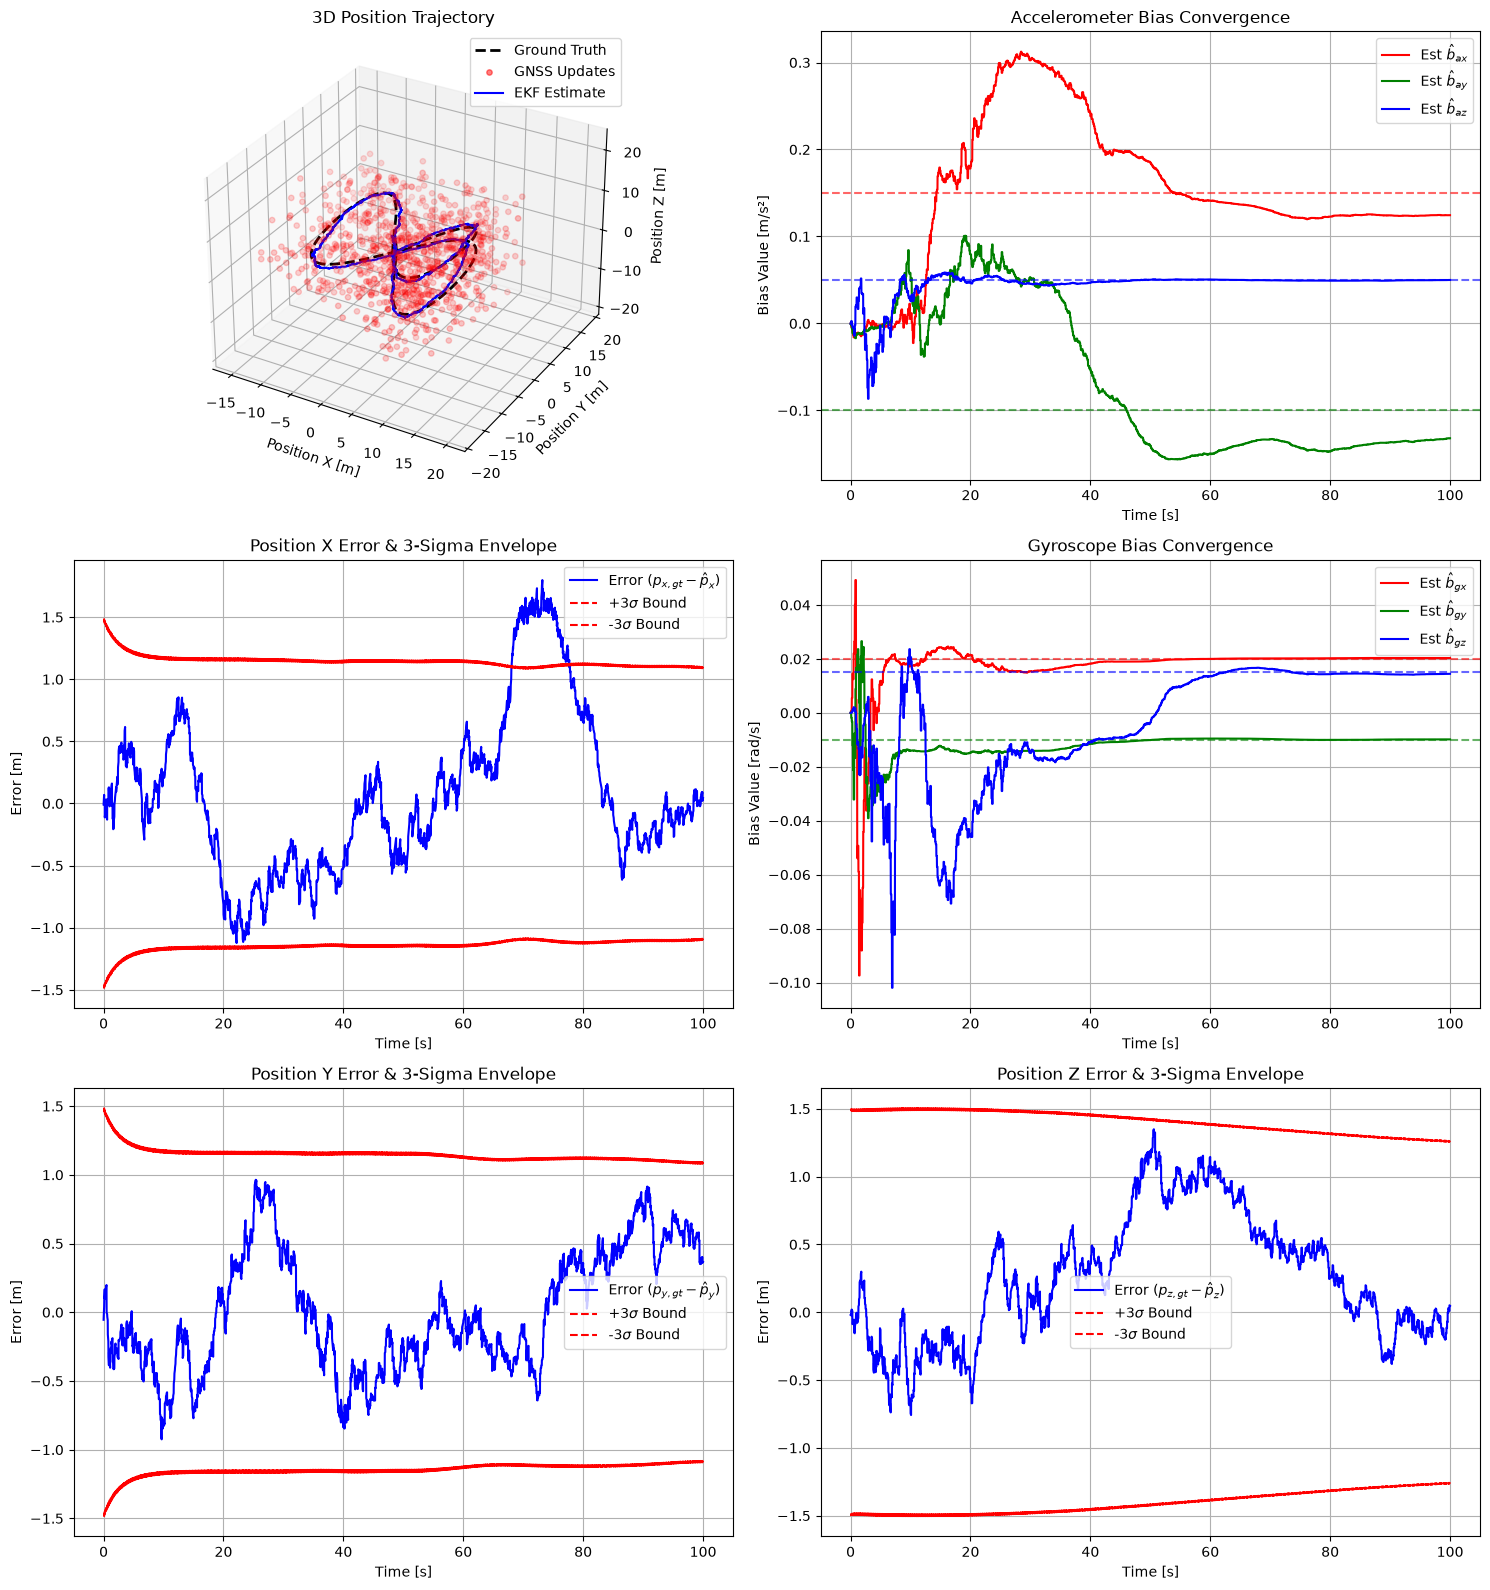

In [ ]:
t, imu_data, gnss_measurements, gt_states, true_biases = generate_synthetic_data(
    duration=100,
    outage_bounds=None,
)

ekf = EKF_3D()

gnss_idx = 0
ekf_states = []
P_history = []

for i in range(len(t)):
    u_k = imu_data[i]
    ekf.predict(u_k)
    
    if gnss_idx < len(gnss_measurements) and gnss_measurements[gnss_idx][0] == i:
        z_k = gnss_measurements[gnss_idx][1]
        ekf.update(z_k)
        gnss_idx += 1
        
    ekf_states.append(ekf.x.copy())
    P_history.append(ekf.P.copy())

plot_ekf_results(t, gt_states, ekf_states, P_history, gnss_measurements, true_biases)

### Simulating Gimbal lock

As we have seen, Euler angle rates suffer from Gimbal lock, which is the loss of one degree of freedom in a multi-dimensional mechanism at certain alignments of the axes. In our case, this happens at $\theta = 90º$. 

$\begin{bmatrix} \dot{\psi} \\ \dot{\theta} \\ \dot{\phi} \end{bmatrix} = B(\psi, \theta, \phi)\omega_B = \begin{bmatrix} 0 & \frac{\sin\phi}{\cos\theta} & \frac{\cos\phi}{\cos\theta} \\ 0 & \cos\phi & -\sin\phi \\ 1 & \frac{\sin\phi\sin\theta}{\cos\theta} & \frac{\cos\phi\sin\theta}{\cos\theta} \end{bmatrix} \begin{bmatrix} \omega_1 \\ \omega_2 \\ \omega_3 \end{bmatrix}_B$

$\hookrightarrow$ At $\theta = \frac{\pi}{2}\; (90^\circ) \rightarrow \cos\theta = 0 \rightarrow \begin{cases} \dot{\psi} \rightarrow \infty \\ \dot{\phi} \rightarrow \infty \end{cases}$

We will generate the same figure 8, but this time introducing a *max_pitch_deg* parameter that determines the maximum pitch angle that the vehicle will reach at some point of the figure 8.

In [30]:
def generate_synthetic_data_gimbal_lock(
        duration=60.0,              # simulation duration (s)
        dt_imu=0.01,                # 100Hz IMU
        dt_gnss=0.1,                # 10Hz gnss  
        outage_bounds=(20.0, 35.0), # gnss outage between 20s and 35s
        seed: int | None = 42,
        fig8_R=10,
        fig8_w=0.1,
        max_pitch_deg=89.8,
        sigma_a=1e-3,               # accel noise
        sigma_w=1e-4,               # gyro noise
        sigma_px=3.0, sigma_py=3.0, sigma_pz=5.0,
        sigma_vx=0.5, sigma_vy=0.5, sigma_vz=0.5
):
    if (outage_bounds is not None) and (outage_bounds[0] > duration):
        print("warn: outage bounds start is higher than duration, wont' be applied")

    if seed is not None:
        np.random.seed(seed)

    t = np.arange(0, duration, dt_imu)
    N = len(t)

    # true sensor biases
    b_ax_true, b_ay_true, b_az_true = 0.15, -0.10, 0.05
    b_gx_true, b_gy_true, b_gz_true = 0.02, -0.01, 0.015

    # ground truth trajectory (Figure-8 in XY, sine wave in Z)
    px_gt = fig8_R * np.sin(fig8_w * t)
    py_gt = fig8_R * np.sin(2 * fig8_w * t)
    pz_gt = 5.0 * np.sin(0.5 * fig8_w * t)
    
    vx_gt = fig8_R * fig8_w * np.cos(fig8_w * t)
    vy_gt = 2 * fig8_R * fig8_w * np.cos(2 * fig8_w * t)
    vz_gt = 5.0 * 0.5 * fig8_w * np.cos(0.5 * fig8_w * t)
    
    ax_gt = -1 * fig8_w**2 * fig8_R * np.sin(fig8_w * t)
    ay_gt = -1 * 4 * fig8_w**2 * fig8_R * np.sin(2 * fig8_w * t)
    az_gt = -5.0 * (0.5 * fig8_w)**2 * np.sin(0.5 * fig8_w * t)
    
    # Sweep pitch up to max_pitch_deg (approaching pi/2)
    theta_amp = np.deg2rad(max_pitch_deg)
    w_pitch = 0.25  # Pitch hits peak at t = pi / (2 * 0.25) = 6.28s

    psi_gt = np.arctan2(vy_gt, vx_gt)
    theta_gt = theta_amp * np.sin(w_pitch * t)
    phi_gt = 0.1 * np.sin(fig8_w * t)

    # Derive rates directly from the angle arrays so they are guaranteed consistent
    psi_dot = np.gradient(np.unwrap(psi_gt), t)
    theta_dot = np.gradient(theta_gt, t)
    phi_dot = np.gradient(phi_gt, t)

    # precompute trig
    c_phi, s_phi = np.cos(phi_gt), np.sin(phi_gt)
    c_theta, s_theta = np.cos(theta_gt), np.sin(theta_gt)
    c_psi, s_psi = np.cos(psi_gt), np.sin(psi_gt)

    # Vectorized true body angular rates (inverse of Euler rate mapping)
    wx_body = phi_dot - psi_dot * s_theta
    wy_body = theta_dot * c_phi + psi_dot * s_phi * c_theta
    wz_body = -theta_dot * s_phi + psi_dot * c_phi * c_theta

    # Vectorized rotation from World to Body: (R_W)^T
    R11, R12, R13 = c_psi * c_theta, s_psi * c_theta, -s_theta
    R21, R22, R23 = c_psi * s_theta * s_phi - s_psi * c_phi, s_psi * s_theta * s_phi + c_psi * c_phi, c_theta * s_phi
    R31, R32, R33 = c_psi * s_theta * c_phi + s_psi * s_phi, s_psi * s_theta * c_phi - c_psi * s_phi, c_theta * c_phi

    # World accelerations (minus gravity) mapped to body frame
    ax_w_adj = ax_gt
    ay_w_adj = ay_gt
    az_w_adj = az_gt - (-9.81)  # Subtracting gravity vector [0, 0, -9.81]

    ax_body = R11 * ax_w_adj + R12 * ay_w_adj + R13 * az_w_adj
    ay_body = R21 * ax_w_adj + R22 * ay_w_adj + R23 * az_w_adj
    az_body = R31 * ax_w_adj + R32 * ay_w_adj + R33 * az_w_adj

    # Observations
    ax_obs = ax_body + b_ax_true + np.random.normal(0, sigma_a, N)
    ay_obs = ay_body + b_ay_true + np.random.normal(0, sigma_a, N)
    az_obs = az_body + b_az_true + np.random.normal(0, sigma_a, N)
    
    wx_obs = wx_body + b_gx_true + np.random.normal(0, sigma_w, N)
    wy_obs = wy_body + b_gy_true + np.random.normal(0, sigma_w, N)
    wz_obs = wz_body + b_gz_true + np.random.normal(0, sigma_w, N)
    
    imu_data = np.vstack([ax_obs, ay_obs, az_obs, wx_obs, wy_obs, wz_obs]).T

    # GNSS Processing
    gnss_ratio = max(1, int(np.round(dt_gnss / dt_imu)))
    gnss_measurements = []

    for i in range(N):
        if i % gnss_ratio == 0:
            current_time = t[i]
            is_outage = (outage_bounds is not None) and (outage_bounds[0] <= current_time <= outage_bounds[1])

            if not is_outage:
                z = np.array([
                    px_gt[i] + np.random.normal(0, sigma_px),
                    py_gt[i] + np.random.normal(0, sigma_py),
                    pz_gt[i] + np.random.normal(0, sigma_pz),
                    vx_gt[i] + np.random.normal(0, sigma_vx),
                    vy_gt[i] + np.random.normal(0, sigma_vy),
                    vz_gt[i] + np.random.normal(0, sigma_vz)
                ])
                gnss_measurements.append((i, z))

    # Compile ground truth and biases for evaluation
    gt_states = np.vstack([px_gt, py_gt, pz_gt, vx_gt, vy_gt, vz_gt, phi_gt, theta_gt, psi_gt]).T
    true_biases = np.array([b_ax_true, b_ay_true, b_az_true, b_gx_true, b_gy_true, b_gz_true])

    return t, imu_data, gnss_measurements, gt_states, true_biases

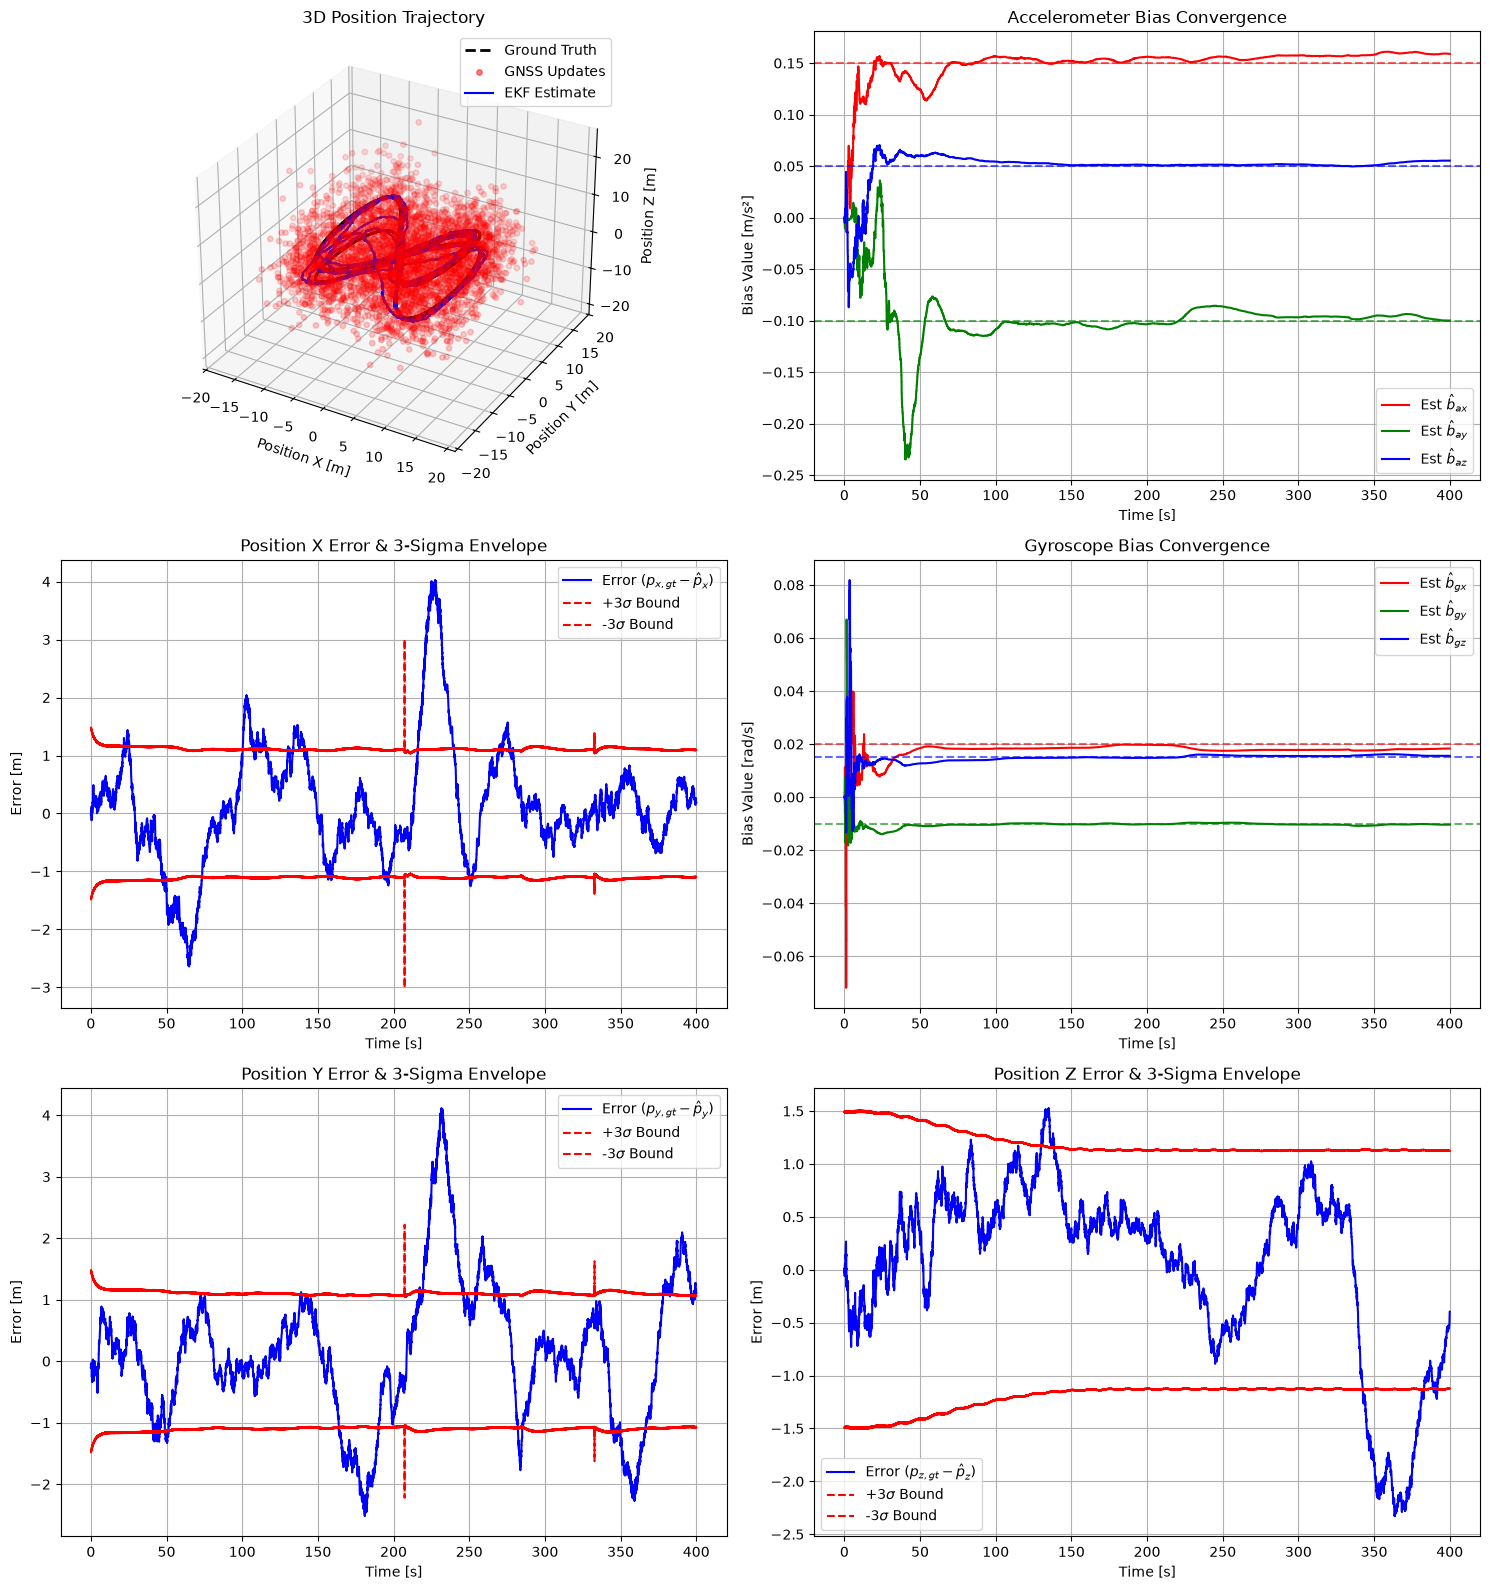

In [72]:
t, imu_data, gnss_measurements, gt_states, true_biases = generate_synthetic_data_gimbal_lock(
    duration=400,
    outage_bounds=None,
    max_pitch_deg=89.9
)

ekf = EKF_3D()

gnss_idx = 0
ekf_states = []
P_history = []

for i in range(len(t)):
    u_k = imu_data[i]
    ekf.predict(u_k)
    
    if gnss_idx < len(gnss_measurements) and gnss_measurements[gnss_idx][0] == i:
        z_k = gnss_measurements[gnss_idx][1]
        ekf.update(z_k)
        gnss_idx += 1
        
    ekf_states.append(ekf.x.copy())
    P_history.append(ekf.P.copy())

plot_ekf_results(t, gt_states, ekf_states, P_history, gnss_measurements, true_biases)

There is no clear explosion of the matrices per se, but the EKF starts behaving weirdly. An "explosion" of the matrices (hitting np.Inf) and subsequent crash of the EKF would only happen if we hit true 90º which we would need to force into the EKF itself (because of noise and floating point arithmetics it does not happen if we manually set max_pitch_deg to 90º).

Nonetheless, crossing the 90º of pitch doesn't produce a single, predictable failure mode; it produces a spectrum of erratic outcomes. In the simulation above, for example, at around 220s, the position error spiked, the biases started moving in different directions and the $P$ $3\sigma$ bounds spiked with a delta. Euler angles can't be trusted in production 3D navigation for this reason.